# STT Evaluation on Google Colab

Set Runtime → Change runtime type → T4 GPU, then run the cells in order.

In [ ]:
# Require a GPU
import torch
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    raise SystemExit("No GPU found. Change the runtime type first.")

CUDA: True
NVIDIA A100-SXM4-40GB


## 1. Get the code

Set `REPO_URL` to your GitHub repo and the cell clones it. Leave the placeholder as is to upload a zip of the repo instead.

In [ ]:
# Get the code: clone from GitHub, or upload a zip as a fallback
import glob, os
from google.colab import files

REPO_URL = "https://github.com/YOUR_USERNAME/stt-eval-kit.git"  # <- change me

!rm -rf kit
if "YOUR_USERNAME" not in REPO_URL:
    !git clone -q {REPO_URL} kit
else:
    uploaded = files.upload()
    zip_name = next(iter(uploaded))
    !unzip -q -o "{zip_name}" -d kit
os.chdir(os.path.dirname(glob.glob("kit/**/run_eval.py", recursive=True)[0]))
print("working dir:", os.getcwd())

## 2. Install

Install the remaining dependencies. `datasets<4` avoids the `torchcodec` issue.

In [ ]:
# Install dependencies
!pip install -q "datasets[audio]<4.0" jiwer librosa soundfile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 90.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


## 3. Run tests

In [ ]:
# Run unit tests
!python -m pytest -q tests

.............                                                            [100%]
13 passed in 18.11s


## 4. Quick run (100 samples, whisper-small)

In [ ]:
# Quick evaluation
!python run_eval.py --max-samples 100 --models openai/whisper-small --batch-size 32

README.md: 100% 386k/386k [00:00<00:00, 262MB/s]

parquet-data/ar_eg/train-00000-of-00001.(…): downloading bytes:   4% 58.8M/1.38G [00:02<00:23, 56.8MB/s, 3.88MB/s  ]
parquet-data/ar_eg/train-00000-of-00001.(…): downloading bytes:   5% 72.5M/1.38G [00:03<00:34, 37.6MB/s, 6.12MB/s  ]
parquet-data/ar_eg/train-00000-of-00001.(…): reconstructing file:   3% 40.5M/1.38G [00:03<02:02, 11.0MB/s, 3.57MB/s  ]
parquet-data/ar_eg/train-00000-of-00001.(…): reconstructing file:   5% 64.0M/1.38G [00:03<00:58, 22.5MB/s, 3.57MB/s  ]
parquet-data/ar_eg/train-00000-of-00001.(…): downloading bytes:   9% 118M/1.38G [00:04<00:26, 48.3MB/s, 8.89MB/s  ]
parquet-data/ar_eg/train-00000-of-00001.(…): downloading bytes:  11% 157M/1.38G [00:04<00:17, 68.2MB/s, 11.7MB/s  ]
parquet-data/ar_eg/train-00000-of-00001.(…): downloading bytes:  13% 173M/1.38G [00:05<00:14, 85.8MB/s, 12.8MB/s  ]
parquet-data/ar_eg/train-00000-of-00001.(…): reconstructing file:  13% 181M/1.38G [00:05<00:19, 60.6MB/s, 13.7MB/s  ]
parquet-data

## 5. Full run (optional)

Full test split, two models.

In [ ]:
# Full evaluation, two models
!python run_eval.py --max-samples 0 --models openai/whisper-small openai/whisper-large-v3-turbo --batch-size 32

Loading weights: 100% 479/479 [00:00<00:00, 5354.65it/s]
[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on its own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).
conditions:   0% 0/10 [00:00<?, ?it/s][transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_toke

## 6. Results

In [ ]:
# Summary tables
import glob
import pandas as pd

for path in sorted(glob.glob("outputs/*/summary_by_condition.csv")):
    print(path)
    cols = ["condition", "wer", "wer_ci_low", "wer_ci_high", "cer", "ins_rate", "rtf", "any_flag_rate"]
    display(pd.read_csv(path)[cols].round(3))

outputs/whisper-large-v3-turbo/summary_by_condition.csv


,condition,wer,wer_ci_low,wer_ci_high,cer,ins_rate,rtf,any_flag_rate
0,clean,0.100,0.088,0.114,0.034,0.005,0.009,0.002
1,white_20dB,0.108,0.095,0.122,0.036,0.005,0.009,0.000
2,white_10dB,0.160,0.147,0.174,0.052,0.009,0.009,0.000
3,white_5dB,0.247,0.232,0.263,0.083,0.012,0.009,0.000
4,telephone,0.112,0.099,0.125,0.038,0.007,0.009,0.002
5,speed_0.85,0.236,0.213,0.262,0.085,0.016,0.009,0.002
6,speed_1.15,0.380,0.319,0.458,0.173,0.071,0.018,0.009
7,low_volume_-25dB,0.101,0.089,0.115,0.034,0.005,0.009,0.002
8,reverb_0.5s,0.181,0.167,0.196,0.059,0.009,0.009,0.000
9,clean_auto_language,0.102,0.089,0.115,0.035,0.005,0.011,0.005


outputs/whisper-small/summary_by_condition.csv


,condition,wer,wer_ci_low,wer_ci_high,cer,ins_rate,rtf,any_flag_rate
0,clean,0.259,0.242,0.276,0.094,0.015,0.033,0.002
1,white_20dB,0.297,0.267,0.339,0.096,0.028,0.033,0.005
2,white_10dB,0.403,0.374,0.446,0.140,0.036,0.033,0.005
3,white_5dB,0.504,0.486,0.524,0.196,0.029,0.034,0.002
4,telephone,0.292,0.275,0.310,0.090,0.015,0.026,0.002
5,speed_0.85,0.533,0.516,0.550,0.206,0.031,0.023,0.000
6,speed_1.15,0.786,0.696,0.903,0.407,0.167,0.074,0.021
7,low_volume_-25dB,0.261,0.244,0.277,0.086,0.013,0.033,0.002
8,reverb_0.5s,0.456,0.423,0.497,0.189,0.044,0.045,0.007
9,clean_auto_language,0.259,0.242,0.276,0.089,0.015,0.035,0.005


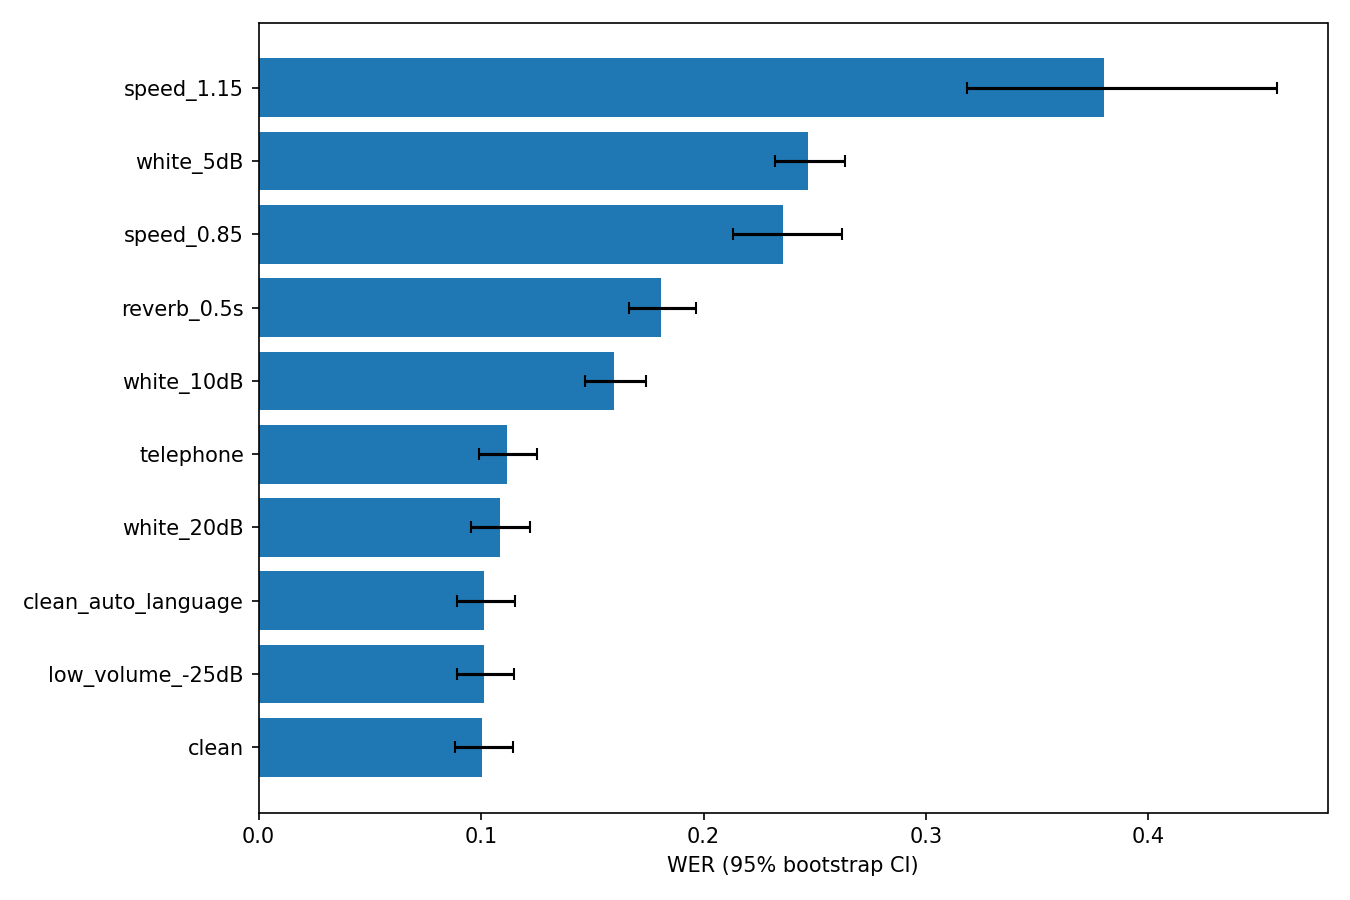

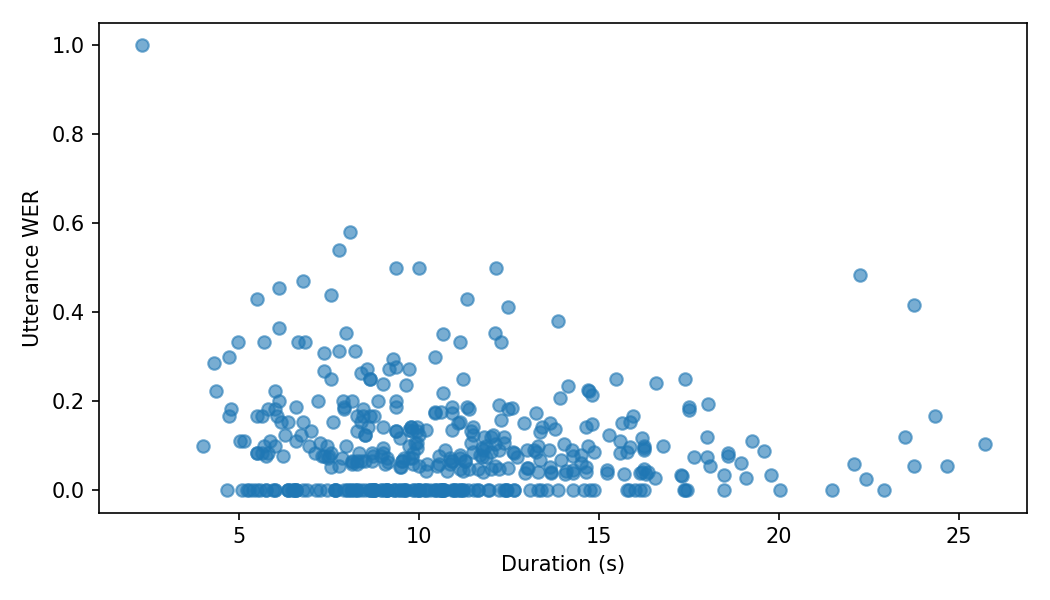

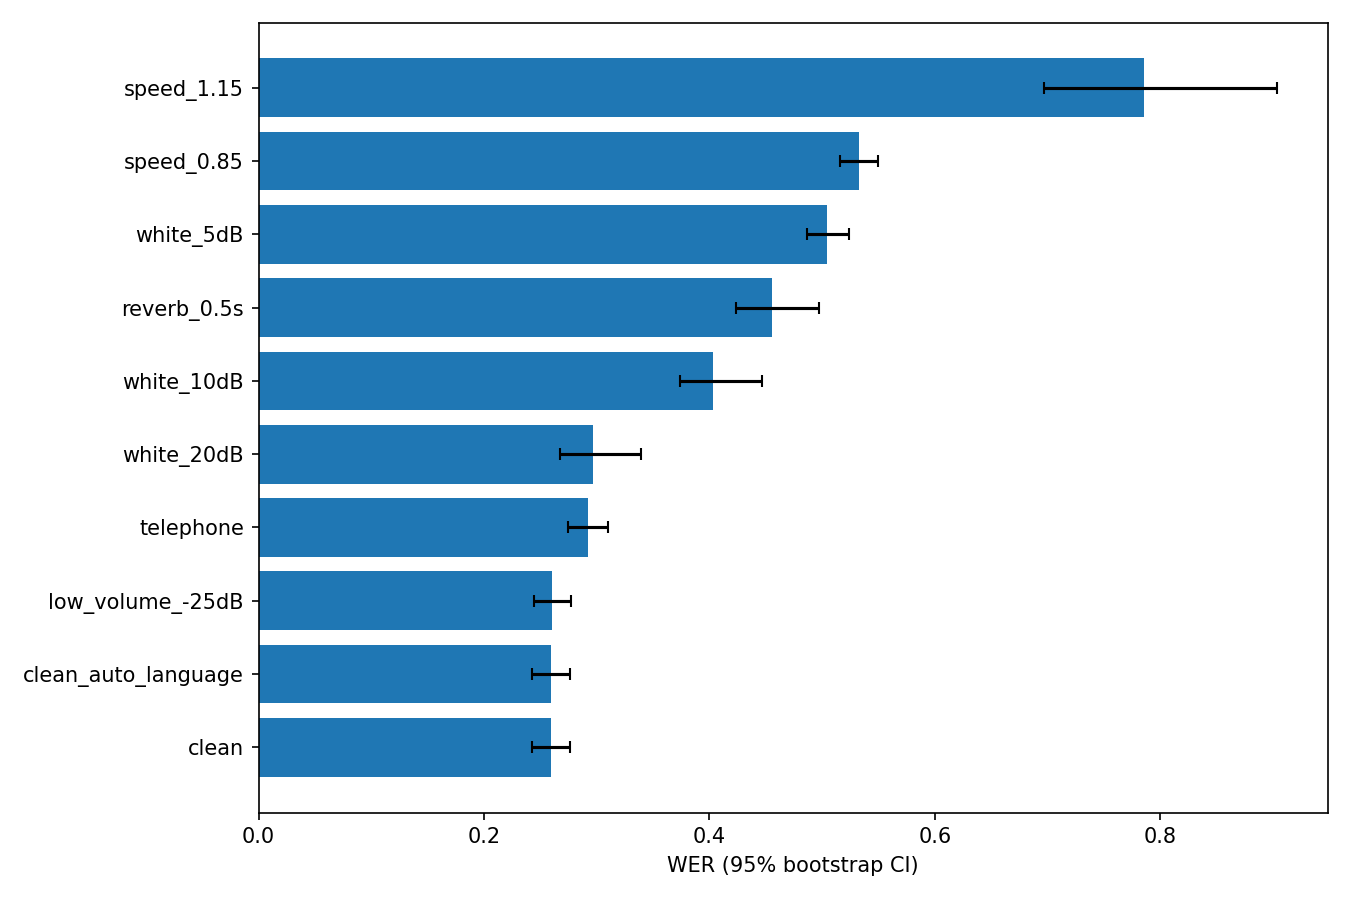

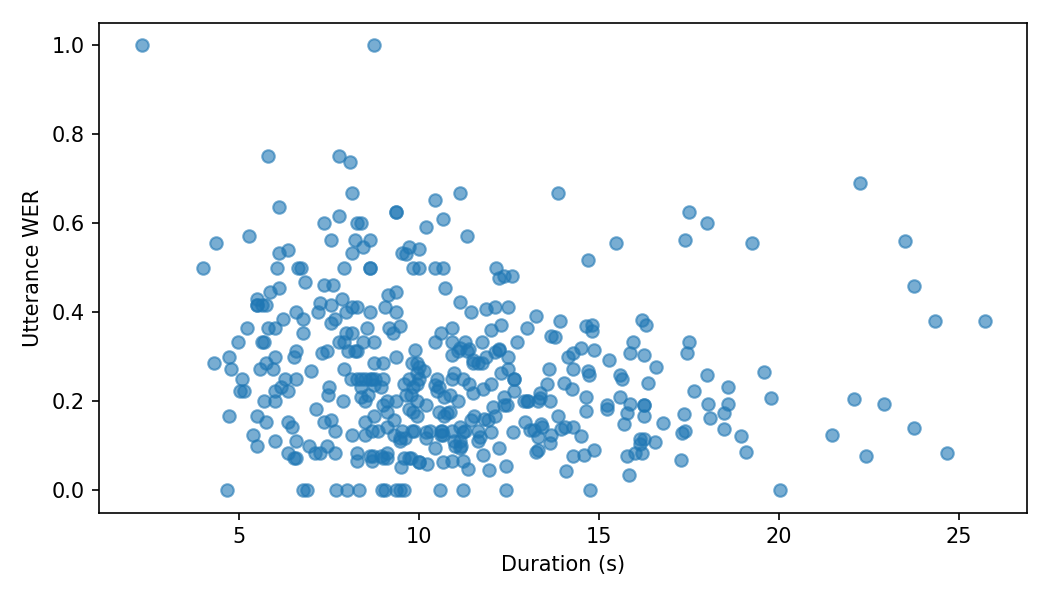

In [ ]:
# Plots
from IPython.display import Image, display

for img in sorted(glob.glob("outputs/*/*.png")):
    display(Image(img))

## 7. Download results

In [ ]:
# Zip and download
!zip -qr outputs.zip outputs
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>